In [22]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [23]:
df_features = pd.read_csv(r"D:\Aswini\EDA\EV_charging\evcharging\Data\EVChargingRecords_Features.csv").drop(columns=["Unnamed: 0"])

In [24]:
print(df_features.columns)

Index(['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType',
       'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime',
       'EndDatetime', 'Duration', 'Demand', 'Duration_seconds',
       'Duration_minutes', 'Duration_hours', 'is_anomaly', 'start day',
       'start month', 'end day', 'end month', 'year', 'day_of_week',
       'is_weekend', 'time_of_day', 'prev_sessions', 'HighDemand'],
      dtype='str')


In [25]:
# --- Step 1: Defining predictors and target ---
X = df_features.drop(columns=['Demand','HighDemand','UserID','ChargerID'])  # drop target + IDs
y = df_features['Demand']   # regression target (continuous)

# --- Step 2: Train/Test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- Step 3: Preprocessing pipeline ---
categorical_columns = ['ChargerCompany','Location','ChargerType','StartDay','StartTime','EndDay','EndTime','time_of_day']
numerical_columns   = ['Duration','Duration_seconds','Duration_minutes','Duration_hours','prev_sessions']
ordinal_columns     = ['start day','start month','end day','end month','year','day_of_week','is_weekend','is_anomaly']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
        ('num', StandardScaler(), numerical_columns),
        ('ord', OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), ordinal_columns)
        
    ],
    remainder='drop'
)

# --- Step 4: Fit preprocessing ---
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed  = preprocessor.transform(X_test)


In [26]:
# Linear Regression
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train_preprocessed, y_train)
y_pred_lin = lin_reg.predict(X_test_preprocessed)

print("Linear Regression Performance")
print("MSE  :", mean_squared_error(y_test, y_pred_lin))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_lin)))
print("MAE  :", mean_absolute_error(y_test, y_pred_lin))
print("R²   :", r2_score(y_test, y_pred_lin))


Linear Regression Performance
MSE  : 143.59095162450097
RMSE : 11.982944196836643
MAE  : 8.317359711319849
R²   : 0.20621925359016402


In [27]:
#Ridge regression
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_train_preprocessed, y_train)
y_pred_ridge = ridge.predict(X_test_preprocessed)

print("Ridge Regression Performance")
print("MSE  :", mean_squared_error(y_test, y_pred_ridge))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print("MAE  :", mean_absolute_error(y_test, y_pred_ridge))
print("R²   :", r2_score(y_test, y_pred_ridge))


Ridge Regression Performance
MSE  : 85.19818590027454
RMSE : 9.230286339018662
MAE  : 6.125408636903245
R²   : 0.5290185152227629


In [28]:
#Lasso Regression
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_train_preprocessed, y_train)
y_pred_lasso = lasso.predict(X_test_preprocessed)

print("Lasso Regression Performance")
print("MSE  :", mean_squared_error(y_test, y_pred_lasso))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))
print("MAE  :", mean_absolute_error(y_test, y_pred_lasso))
print("R²   :", r2_score(y_test, y_pred_lasso))


Lasso Regression Performance
MSE  : 75.65031537608516
RMSE : 8.697718975460472
MAE  : 5.533532472223271
R²   : 0.5817998061437595


In [29]:
# Random Forest regression
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(
    n_estimators=200, 
    max_depth=10, 
    random_state=42, 
    n_jobs=-1
)
rf_reg.fit(X_train_preprocessed, y_train)
y_pred_rf = rf_reg.predict(X_test_preprocessed)

print("Random Forest Regressor Performance")
print("MSE  :", mean_squared_error(y_test, y_pred_rf))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MAE  :", mean_absolute_error(y_test, y_pred_rf))
print("R²   :", r2_score(y_test, y_pred_rf))


Random Forest Regressor Performance
MSE  : 36.267183101620994
RMSE : 6.022224099252783
MAE  : 3.368732692286226
R²   : 0.799512494715755


In [30]:
# Xgboost Regression
from xgboost import XGBRegressor

xgb_reg = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_reg.fit(X_train_preprocessed, y_train)
y_pred_xgb = xgb_reg.predict(X_test_preprocessed)

print("XGBoost Regressor Performance")
print("MSE  :", mean_squared_error(y_test, y_pred_xgb))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_xgb)))
print("MAE  :", mean_absolute_error(y_test, y_pred_xgb))
print("R²   :", r2_score(y_test, y_pred_xgb))


XGBoost Regressor Performance
MSE  : 36.86110801778843
RMSE : 6.071334945280851
MAE  : 3.446830319678078
R²   : 0.796229236558238


In [31]:
# Light gradient boost regression
import lightgbm as lgb

# Initializing LightGBM Regressor
lgb_reg = lgb.LGBMRegressor(
    boosting_type='gbdt',
    objective='regression',
    n_estimators=300,
    learning_rate=0.1,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1 
)

lgb_reg.fit(X_train_preprocessed, y_train)

y_pred_lgb = lgb_reg.predict(X_test_preprocessed)

print("LightGBM Regressor Performance")
print("MSE  :", mean_squared_error(y_test, y_pred_lgb))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_lgb)))
print("MAE  :", mean_absolute_error(y_test, y_pred_lgb))
print("R²   :", r2_score(y_test, y_pred_lgb))


LightGBM Regressor Performance
MSE  : 34.41649028684246
RMSE : 5.866556936299388
MAE  : 3.307770950457716
R²   : 0.8097432530418915


## Regression Model Comparison

| Model | MSE | RMSE | MAE | R² Score |
|---------|---------:|---------:|---------:|---------:|
| Linear Regression | 143.59 | 11.98 | 8.32 | 0.2062 |
| Ridge Regression | 85.20 | 9.23 | 6.13 | 0.5290 |
| Lasso Regression | 75.65 | 8.70 | 5.53 | 0.5818 |
| Random Forest Regressor | 36.27 | 6.02 | 3.37 | 0.7995 |
| XGBoost Regressor | 36.86 | 6.07 | 3.45 | 0.7962 |
| LightGBM Regressor | **34.42** | **5.87** | **3.31** | **0.8097** |


In [32]:
# Predictions comparision for Random forest
y_train_pred = rf_reg.predict(X_train_preprocessed)
y_test_pred  = rf_reg.predict(X_test_preprocessed)

# Row-level comparison for test set
comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred,
    "Residual": y_test.values - y_test_pred
})

# Overall metrics
train_r2 = r2_score(y_train, y_train_pred)
test_r2  = r2_score(y_test, y_test_pred)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae  = mean_absolute_error(y_test, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse  = np.sqrt(mean_squared_error(y_test, y_test_pred))

metrics_df = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "R2": [train_r2, test_r2],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse]
})

print("Row-level comparison (first 10 rows):")
print(comparison_df.head(10))

print("\nOverall performance metrics:")
print(metrics_df)


Row-level comparison (first 10 rows):
   Actual  Predicted   Residual
0   69.30  55.600115  13.699885
1   18.18  17.499839   0.680161
2   49.18  49.508204  -0.328204
3    0.20   0.276175  -0.076175
4    4.70   4.113952   0.586048
5    3.70   5.625216  -1.925216
6   20.10  20.160166  -0.060166
7    2.47   2.196106   0.273894
8    4.40   3.803240   0.596760
9   20.50  19.767427   0.732573

Overall performance metrics:
  Dataset        R2       MAE      RMSE
0   Train  0.844551  3.157640  5.307698
1    Test  0.799512  3.368733  6.022224


In [33]:
# # Predictions comparision for Xgboost
y_train_pred = xgb_reg.predict(X_train_preprocessed)
y_test_pred  = xgb_reg.predict(X_test_preprocessed)

# Row-level comparison for test set
comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred,
    "Residual": y_test.values - y_test_pred
})

# Overall metrics
train_r2 = r2_score(y_train, y_train_pred)
test_r2  = r2_score(y_test, y_test_pred)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae  = mean_absolute_error(y_test, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse  = np.sqrt(mean_squared_error(y_test, y_test_pred))

metrics_df = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "R2": [train_r2, test_r2],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse]
})

print("Row-level comparison (first 10 rows):")
print(comparison_df.head(10))

print("\nOverall performance metrics:")
print(metrics_df)


Row-level comparison (first 10 rows):
   Actual  Predicted   Residual
0   69.30  56.147190  13.152810
1   18.18  18.194632  -0.014632
2   49.18  49.600323  -0.420323
3    0.20   0.562715  -0.362715
4    4.70   4.654561   0.045439
5    3.70   5.646053  -1.946053
6   20.10  19.419584   0.680416
7    2.47   2.851632  -0.381632
8    4.40   4.568418  -0.168418
9   20.50  20.426151   0.073849

Overall performance metrics:
  Dataset        R2       MAE      RMSE
0   Train  0.838174  3.283753  5.415466
1    Test  0.796229  3.446830  6.071335


In [34]:
# # Predictions comparision for Light gradient boost
y_train_pred = lgb_reg.predict(X_train_preprocessed)
y_test_pred  = lgb_reg.predict(X_test_preprocessed)

# Row-level comparison for test set
comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred,
    "Residual": y_test.values - y_test_pred
})

# Overall metrics
train_r2 = r2_score(y_train, y_train_pred)
test_r2  = r2_score(y_test, y_test_pred)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae  = mean_absolute_error(y_test, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse  = np.sqrt(mean_squared_error(y_test, y_test_pred))

metrics_df = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "R2": [train_r2, test_r2],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse]
})

print("Row-level comparison (first 10 rows):")
print(comparison_df.head(10))

print("\nOverall performance metrics:")
print(metrics_df)


Row-level comparison (first 10 rows):
   Actual  Predicted  Residual
0   69.30  61.354866  7.945134
1   18.18  16.990325  1.189675
2   49.18  50.598911 -1.418911
3    0.20  -0.222093  0.422093
4    4.70   4.333140  0.366860
5    3.70   5.519354 -1.819354
6   20.10  19.576299  0.523701
7    2.47   2.591589 -0.121589
8    4.40   4.510390 -0.110390
9   20.50  20.486476  0.013524

Overall performance metrics:
  Dataset        R2       MAE      RMSE
0   Train  0.855860  3.031232  5.110982
1    Test  0.809743  3.307771  5.866557


In [35]:
print(X_test_preprocessed.dtype)

float64


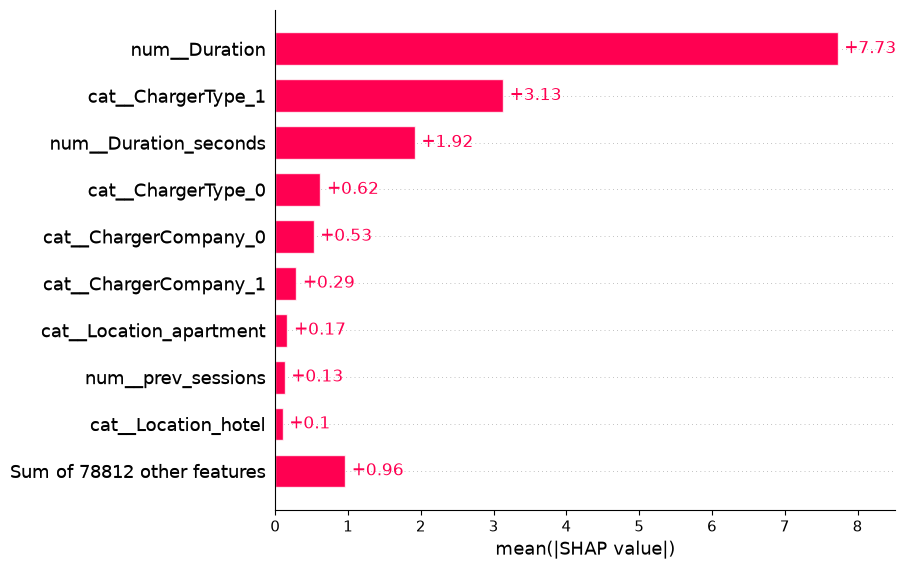

In [36]:
import shap

X_sample = X_test_preprocessed[:500].toarray()

explainer_rf = shap.TreeExplainer(rf_reg)

shap_values_rf = explainer_rf.shap_values(X_sample)

feature_names = preprocessor.get_feature_names_out()

X_sample_df = pd.DataFrame(
    X_test_preprocessed[:500].toarray(),
    columns=feature_names
)

explainer_rf = shap.Explainer(rf_reg)
shap_values_rf = explainer_rf(X_sample_df)

shap.plots.bar(shap_values_rf)

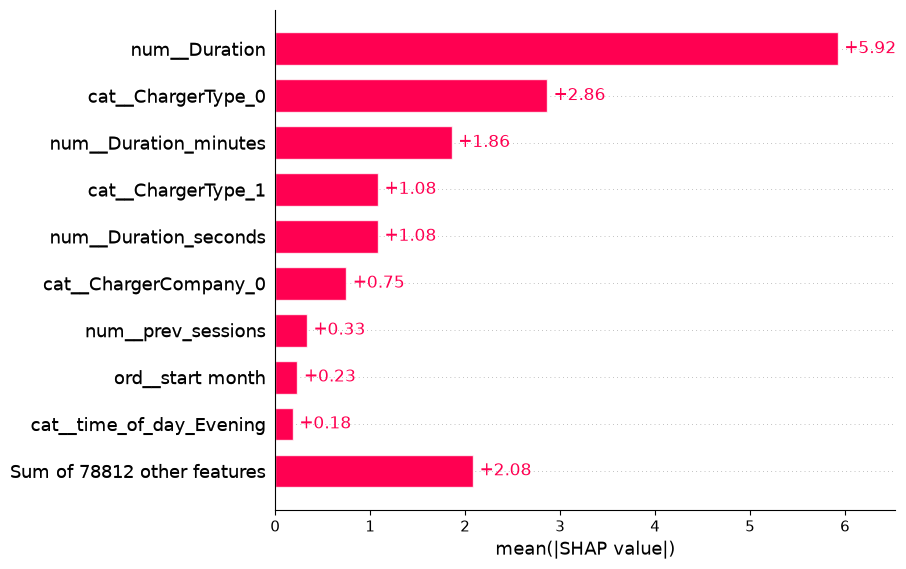

In [37]:
import shap
import pandas as pd

# Sample rows for SHAP
X_sample_df = pd.DataFrame(
    X_test_preprocessed[:500].toarray(),
    columns=preprocessor.get_feature_names_out()
)

# SHAP Explainer for LightGBM
explainer_lgb = shap.Explainer(lgb_reg)

# Calculate SHAP values
shap_values_lgb = explainer_lgb(X_sample_df)

# Feature Importance Bar Plot
shap.plots.bar(shap_values_lgb)

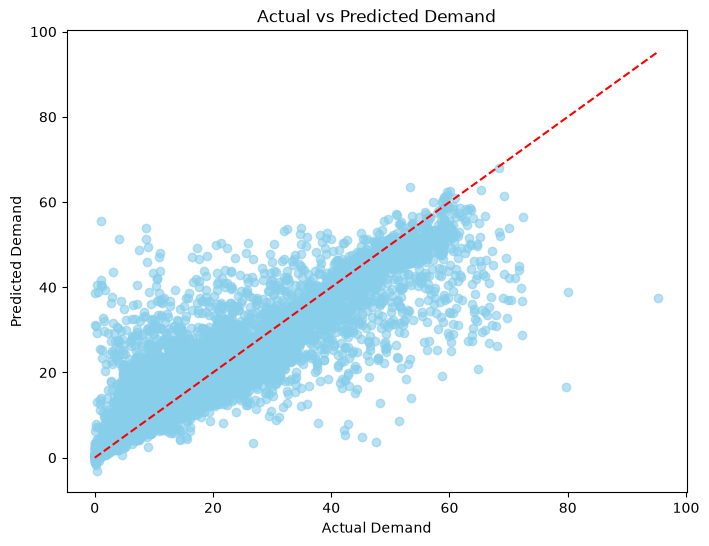

In [38]:
y_pred = lgb_reg.predict(X_test_preprocessed)

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.6, color="skyblue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # perfect fit line
plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Actual vs Predicted Demand")
plt.show()


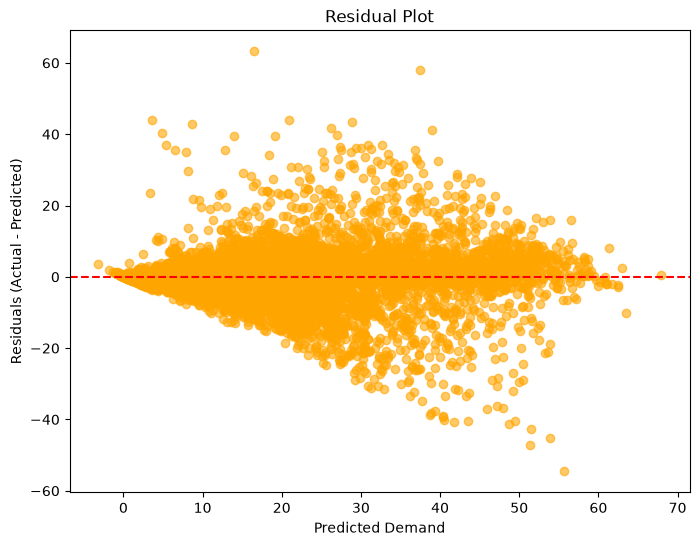

In [39]:
residuals = y_test - y_pred

plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals, alpha=0.6, color="orange")
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Demand")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()


In [40]:
import pickle
pickle.dump((lgb_reg,preprocessor), open('regression_model.pkl','wb'))

In [42]:
# lgb_reg was fit on X_train_preprocessed, which came from this same preprocessor
print(lgb_reg.n_features_in_, X_train_preprocessed.shape[1])   # must match

pickle.dump((lgb_reg, preprocessor), open("regression_model.pkl", "wb"))

78821 78821
